# KPI Stat Tile (big number)

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

When the story is one number, the best chart is the number itself. A large value with a label, a change versus a comparison period, and an optional sparkline answers 'how are we doing?' instantly.

## When to use

- A single headline metric (one-bar charts and 2-slice pies should be tiles instead)
- Show the top row of a dashboard
- Show a value whose context is a change versus last period or target

## Avoid when

- Comparisons between many items are needed (use a chart)
- The number is meaningless without a distribution or trend (add a sparkline or chart)

## Alternatives

- Bullet chart
- Sparklines table

## Design tips

- Show the delta with a sign and arrow, not only color
- Use status colors only when the change has a good/bad meaning

## Example

Four headline KPIs with deltas and 12-week sparklines.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(3)
tiles = [
    ("Monthly revenue", "$1.24M", "+8.2% vs last month", True, np.cumsum(rng.normal(1, 1, 12))),
    ("Active users", "48.9k", "+3.1% vs last month", True, np.cumsum(rng.normal(.5, 1, 12))),
    ("Churn rate", "2.7%", "+0.4 pts vs last month", False, np.cumsum(rng.normal(.3, 1, 12))),
    ("Support tickets", "312", "−12% vs last month", True, np.cumsum(rng.normal(-.5, 1, 12))),
]
pd.DataFrame(tiles, columns=["label", "value", "delta", "good", "trend"]).drop(columns="trend")

,label,value,delta,good
0,Monthly revenue,$1.24M,+8.2% vs last month,True
1,Active users,48.9k,+3.1% vs last month,True
2,Churn rate,2.7%,+0.4 pts vs last month,False
3,Support tickets,312,−12% vs last month,True


### Plot

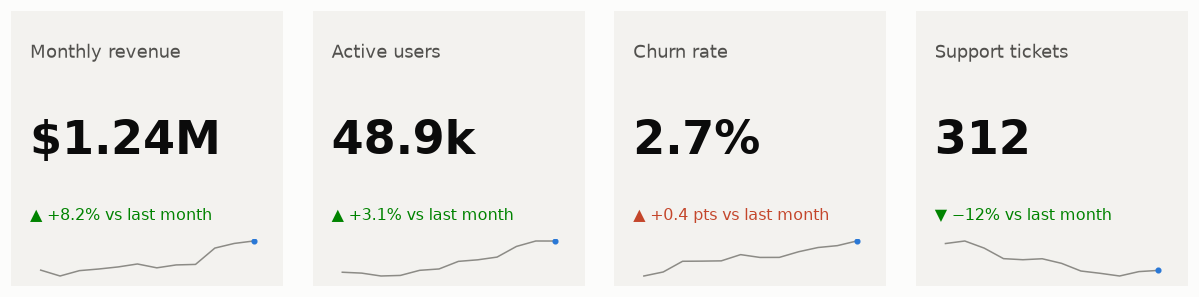

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, (label, value, delta, good, trend) in zip(axes, tiles):
    ax.set_facecolor("#f3f2ef")
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.text(0.07, 0.83, label, transform=ax.transAxes, fontsize=12, color="#52514e")
    ax.text(0.07, 0.48, value, transform=ax.transAxes, fontsize=30, fontweight="bold")
    arrow = "▲" if delta.startswith("+") else "▼"
    ax.text(0.07, 0.24, f"{arrow} {delta}", transform=ax.transAxes, fontsize=10.5,
            color="#008300" if good else "#c4462b")
    ins = ax.inset_axes([0.07, 0.03, 0.86, 0.14])
    ins.plot(trend, color="#8c8b86", linewidth=1)
    ins.plot(len(trend) - 1, trend[-1], "o", color=PALETTE[0], markersize=3)
    ins.axis("off")
fig.tight_layout(w_pad=1.5)
plt.show()

## How to read it

Each tile gives one metric, its change, and a 12-week trend. Arrows and text carry the direction. Color only adds whether the change is good (green) or bad (red), so it never carries meaning alone.

---
Standalone script: [`kpi_stat_tile.py`](kpi_stat_tile.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)